# ***About The Dataset***

**Netflix is one of the most popular media and video streaming platforms. They have over 10000 movies or tv shows available on their platform, as of mid-2021, they have over 222M Subscribers globally. This tabular dataset consists of listings of all the movies and tv shows available on Netflix, along with details such as - cast, directors, ratings, release year, duration, etc.**

# ***Business Problem***

**Analyze the data and generate insights that could help Netflix ijn deciding which type of shows/movies to produce and how they can grow the business in different countries**

# **Import Required Libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Loading The Data

In [3]:
!gdown https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/000/940/original/netflix.csv

Downloading...
From: https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/000/940/original/netflix.csv
To: /content/netflix.csv
100% 3.40M/3.40M [00:00<00:00, 44.0MB/s]


In [4]:
data=pd.read_csv('netflix.csv')

# <p><font size="5" color="#1A73E8"><b>1. 🔍Analysing basic metrics and shape






In [5]:
data.head() # initial 5 records of data

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
print("Shape of dataset:", data.shape)

Shape of dataset: (8807, 12)


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
 The Dataset contains 8807 rows and 12 columns. Each row represents a single
Movie or TV Show listed on Netflix, with attributes covering the title, director,
cast, country of production, date added to Netflix, release year, content rating,
duration, genre (listed_in), and description

# <p><font size="5" color="#1A73E8"><b>2. 🧠Observations on the data types of all the attributes, missing value detection, statistical summary

In [7]:
data.dtypes # data types of all attributes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


**Info-** All columns except 'release year' are stored as object and  no need to change type conversion of actegorical as dataset is not large

#  <p><font size="5" color="#1A73E8"><b> 5. Missing Value & Outlier check (Treatment optional)

# 🧩 **Missing value detection and percentage of it in data**

In [8]:
(data.isnull().sum()/len(data)*100).round(2)

,0
show_id,0.00
type,0.00
title,0.00
director,29.91
cast,9.37
country,9.44
date_added,0.11
release_year,0.00
rating,0.05
duration,0.03


* **Data Deficits:** The 'director' column exhibits the highest missingness at **29.91%**, followed by moderate gaps in columns 'country' and 'cast' (**nearly 10%**), while 'date_added', 'rating', and 'duration' column remain nearly complete with negligible omissions under 0.2%.






# 🛠️ Handle missing values

 # 🧼 Categorical:fill with Unknown_column_name

In [9]:
data['director'] = data['director'].fillna('Unknown_Director')
data['cast'] = data['cast'].fillna('Unknown_Cast')
data['country'] = data['country'].fillna('Unknown_Country')
data['rating'] = data['rating'].fillna('Unknown_Rating')

# ✂️ Very few nulls (date_added, duration) - safe to drop

In [10]:
data = data.dropna(subset=['date_added', 'duration'])

data.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


# Insights
Dataset is now 100% clean and free of null values

Filled missing categorical values with unknown specific column name and numerical value with zero

Row dropped <0.2% of incomplete rows from the entire data

In [11]:
# Statistical Summery
data.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8794,8794,8794,8794,8794,8794,8794,8794.000000,8794,8794,8794,8794
unique,8794,2,8794,4528,7682,749,1766,NaN,15,220,513,8762
top,s8807,Movie,Zubaan,Unknown_Director,Unknown_Cast,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6128,1,2624,825,2809,109,NaN,3205,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.183534,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.823527,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [12]:
# Types of Contents available in proportion
data['type'].value_counts(normalize=True)*100

,proportion
type,
Movie,69.683875
TV Show,30.316125


## Statistical Summary
- Over 75% of Netflix's catalog consists of modern content released after 2013,
50% of data consist from 2013 to 2019

- Movies (6128) outnumber TV Shows on the platform — roughly 70/30.
- "United States" is the single most common country of production.
- TV-MA is the most frequent content rating, showing the catalog
  skews toward mature audiences nearly 30 percentage of data.
- "Dramas, International Movies" is the most common genre combination.
- Most TV Shows run for just "1 Season" (1793 titles)

# **Defining Some Basic Problem Statement & Manipulation**

### Feature Preparation: Renaming Columns for Clarity

In [13]:
data=data.rename(columns={'listed_in':'genre'})
data.head(2)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown_Cast,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown_Director,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."


# **Bifurcate Data by Content Type and preparation of the data for Analysis**

# Feature Creation: Temporal and Quantitative Attribute Extraction for Both Datasets

### For Movies Dataframe // Filter Movies

In [14]:
data_movies=data.loc[data['type']=='Movie']

In [111]:
#Converting Raw Text Attributes to Actionable Metrics
data_movies['Number of Session']=data_movies['duration'].str.extract(r'(\d+)').astype(int)

In [111]:
# Data Transformation: Standardizing DateTime Metrics
data_movies['datetime']=pd.to_datetime(data_movies['date_added'].str.strip())

In [111]:
# Extracting Content Addition Year based on movie added in netflix
data_movies['added year']=data_movies['datetime'].dt.year

In [111]:
#Extracting Month name based on movie added in netflix
data_movies['Month Name']=data_movies['datetime'].dt.month_name()

In [111]:
#Extracting Year & Week based on movie added in netflix
data_movies['week'] = data_movies['datetime'].dt.strftime('W%V')

In [111]:
#Create a datetime object for the release year and assuming Jan 1st of the release year as the apprx date
data_movies['release_date_approx'] = pd.to_datetime(data_movies['release_year'].astype(str) + '-01-01')

In [111]:
# Calculate difference in days
data_movies['days_to_netflix'] = (data_movies['datetime'] - data_movies['release_date_approx']).dt.days

### For TV_Show Dataframe // Filter TV Shows

In [22]:
data_tv=data.loc[data['type']=='TV Show']

In [111]:
#Converting Raw Text Attributes to Actionable Metrics
data_tv['Number of Session']=data_tv['duration'].str.extract(r'(\d+)').astype(int)

In [111]:
# Data Transformation: Standardizing DateTime Metrics
data_tv['datetime']=pd.to_datetime(data_tv['date_added'].str.strip())

In [111]:
# Extracting Content Addition Year based on TV Shows added in netflix
data_tv['added year']=data_tv['datetime'].dt.year

In [111]:
#Extracting Month name based on TV Shows added in netflix
data_tv['Month Name']=data_tv['datetime'].dt.month_name()

In [111]:
#Extracting Week based on movie added in netflix
data_tv['week'] = data_tv['datetime'].dt.strftime('W%V')

In [111]:
#Create a datetime object for the release year and assuming Jan 1st of the release year as the apprx date
data_tv['release_date_approx'] = pd.to_datetime(data_tv['release_year'].astype(str) + '-01-01')

In [111]:
# Calculate difference in days
data_tv['days_to_netflix'] = (data_tv['datetime'] - data_tv['release_date_approx']).dt.days

In [111]:
# Description of the Both datasets
print(data_movies.info())
print(data_tv.info())


<class 'pandas.core.frame.DataFrame'>
Index: 6128 entries, 0 to 8806
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   show_id              6128 non-null   object        
 1   type                 6128 non-null   object        
 2   title                6128 non-null   object        
 3   director             6128 non-null   object        
 4   cast                 6128 non-null   object        
 5   country              6128 non-null   object        
 6   date_added           6128 non-null   object        
 7   release_year         6128 non-null   int64         
 8   rating               6128 non-null   object        
 9   duration             6128 non-null   object        
 10  genre                6128 non-null   object        
 11  description          6128 non-null   object        
 12  Number of Session    6128 non-null   int64         
 13  datetime             6128 non-null   d

**Distribution :**
The dataset split between 70/30 catalog  Movies (6,128) and TV Shows (2,666), with 100% complete records across 17 features

**Feature Readiness:**
Extracted duration metrics and temporal variables like added year, Month Name, year_week

# **🔬 Data Preparation For Analysis**

# unnest some of column in the data for getting pin point analysis

In [31]:
def unnest(data, col):
    temp = data.copy()
    temp[col] = temp[col].str.split(', ')
    temp = temp.explode(col)
    temp[col] = temp[col].str.strip()
    return temp

# Un-nesting Movies and TV Shows Separately

To compare countries and genres between Movies and TV Shows independently, the
country,cast and genre columns were un-nested separately within data_movies and
data_tv.
which allows accurate top-10 country/genre/cast breakdowns for each content
type, rather than mixing movies and TV shows together.

# Unnest Geography for movies and TV shows separately

In [32]:
data_mov_country = unnest(data_movies, 'country')

In [33]:
data_tv_country = unnest(data_tv, 'country')


# Unnest genre for movies and TV shows separately

In [34]:
data_mov_genre = unnest(data_movies, 'genre')


In [35]:
data_tv_genre = unnest(data_tv, 'genre')


# Unnest cast for movies and TV shows separately

In [36]:
data_mov_cast = unnest(data_movies, 'cast')


In [37]:
data_tv_cast = unnest(data_tv, 'cast')

# Unnest Directors for movies and TV shows separately

In [38]:
data_mov_dir = unnest(data_movies, 'director')

In [39]:
data_tv_dir = unnest(data_tv, 'director')

# One  Clean Data

In [40]:
movie_genre=unnest(data_mov_country,'genre')
movie_cast=unnest(movie_genre,'cast')
clean_movie=unnest(movie_cast,'director')

In [41]:
tv_genre=unnest(data_tv_country,'genre')
tv_cast=unnest(tv_genre,'cast')
clean_tv=unnest(tv_cast,'director')

 **Eliminated Composite Bias & Granular Precision from data**
Exploding comma-separated values enables accurate individual counts for actors, directors, genres, and production countries.


# <p><font size="5" color="#1A73E8"><b>3. 🔢 Non-Graphical Analysis: Value Counts and Unique Attributes

# **(A) Geographical Analysis**

In [42]:
top_10_country_TV=data_tv_country[data_tv_country['country']!='Unknown_Country']['country'].value_counts().head(10)
top_10_country_TV

,count
country,
United States,932
United Kingdom,271
Japan,198
South Korea,170
Canada,126
France,90
India,84
Taiwan,70
Australia,65


In [43]:
top_10_country_M=data_mov_country[data_mov_country['country']!='Unknown_Country']['country'].value_counts().head(10)
top_10_country_M

,count
country,
United States,2748
India,962
United Kingdom,532
Canada,319
France,303
Germany,182
Spain,171
Japan,119
China,114


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>


**Majority of TV_Shows were released in USA**
*    UK,Japan,South Korea & Canada also have significant market share of Netflix
 **USA & India dominate the movie catalog**
*    UK,Canada,France  also have signifiacnt amounts of share of the Netflix contents

* So its clear that Netflix more focus regional dramas and series like asian,anime and uk but in the context of movies netflix focus on international movies specially Hollywood and Bollywood

# **(B) Top 10 Directors Based on Movies & TV Shows Production**

In [44]:
top_10_dir_M=data_mov_dir[data_mov_dir['director']!='Unknown_Director']['director'].value_counts().head(10)
top_10_dir_M

,count
director,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Jay Karas,15
Marcus Raboy,15
Cathy Garcia-Molina,13
Martin Scorsese,12
Youssef Chahine,12


In [45]:
top_10_dir_TV=data_tv_dir[data_tv_dir['director']!='Unknown_Director']['director'].value_counts().head(10)
top_10_dir_TV

,count
director,
Ken Burns,3
Alastair Fothergill,3
Hsu Fu-chun,2
Stan Lathan,2
Iginio Straffi,2
Joe Berlinger,2
Lynn Novick,2
Rob Seidenglanz,2
Jung-ah Im,2


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
As per the analysis based on directors mostly kids friendly director based on productive directors like comedy, animation etc
In the Tv Shows type mostly based on east asia which reflects regional contents

# **(C) Top 10 Cast Based on Movies & TV Shows Production**

In [46]:
top_10_cast_M=data_mov_cast[data_mov_cast['cast']!='Unknown_Cast']['cast'].value_counts().head(10)
top_10_cast_M

,count
cast,
Anupam Kher,42
Shah Rukh Khan,35
Naseeruddin Shah,32
Akshay Kumar,30
Om Puri,30
Paresh Rawal,28
Julie Tejwani,28
Amitabh Bachchan,28
Boman Irani,27


In [47]:
top_10_cast_tv=data_tv_cast[data_tv_cast['cast']!='Unknown_Cast']['cast'].value_counts().head(10)
top_10_cast_tv

,count
cast,
Takahiro Sakurai,25
Yuki Kaji,19
Ai Kayano,17
Junichi Suwabe,17
Daisuke Ono,17
Yuichi Nakamura,16
Jun Fukuyama,15
Yoshimasa Hosoya,15
David Attenborough,14


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
Netflix heavily leverages star power from India for film consumption and East Asian talent for TV Shows
 As the most productive cast from movie listed are from bollywood and TV Shows listed are from east asia
 also voice cast also appeared in the top list from both movie and TV Shows

# **(D) Release Trends Across Movies & TV Shows**

In [48]:
release_trend_m=data_movies['datetime'].dt.year.value_counts().head(10)
release_trend_m

,count
datetime,
2019,1424
2020,1284
2018,1237
2021,993
2017,838
2016,251
2015,56
2014,19
2011,13


In [49]:
release_trend_tv=data_tv['datetime'].dt.year.value_counts().head(10)
release_trend_tv

,count
datetime,
2020,595
2019,592
2021,505
2018,412
2017,349
2016,176
2015,26
2014,5
2013,5


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
Over 90% of all titles currently on Netflix were added in the last 6 years, ensuring the platform maintains a constantly refreshed, highly active content library

2019–2020 Platform Peak: Reason might be covid era and

2021 production trends shown decrease: reason might be lack of data because this data end range mid of 2021

volume of movie is 2.5 times more than TV Shows

# (E)**Strategic Timing for Maximum Engagement & Retention**

In [50]:
data_movies['week'].value_counts().head(10)

,count
week,
W01,316
W44,243
W40,215
W09,207
W26,195
W35,189
W31,185
W13,174
W18,173


In [51]:
data_tv['week'].value_counts().head(10)

,count
week,
W27,86
W31,83
W13,76
W44,75
W24,75
W35,74
W05,73
W26,73
W40,72


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

for movie W40 to w44 is most favourable for release any movie  because its the week of octoberearly holiday-season momentum

for tv shows W26 – W31 (July to Early August)
Summer breaks for schools and universities lead to elevated daytime and late-night binge-watching

w48-w52 also shown high volume of tv shows engagement might be year end as the reason


# **(F) Distribution of Target Audience Ratings by Category For Both Movies and TV_Shows**

In [52]:
rate_m=data_movies['rating'].value_counts().head(10)
rate_m

,count
rating,
TV-MA,2062
TV-14,1427
R,797
TV-PG,540
PG-13,490
PG,287
TV-Y7,139
TV-Y,131
TV-G,126


In [53]:
rate_tv=data_tv['rating'].value_counts().head(10)
rate_tv

,count
rating,
TV-MA,1143
TV-14,730
TV-PG,321
TV-Y7,194
TV-Y,175
TV-G,94
NR,4
R,2
Unknown_Rating,2


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
**Dominance of Mature Audiences (TV-MA & R):** Across both formats, TV-MA is the leading rating ( nearly 33% of movies and nearly 43% of TV shows),

Netflix's content strategy heavily targets adult/mature demographics.

TV-14 forms the second-largest category for both Movies and TV Shows, ensuring a strong catalog for teen and general family viewing.

kids friendly TV-Y, TV-Y7, TV-G makes up a smaller share, but remains highly concentrated in dedicated animated franchises and family series.

# **(G) Content Duration Analysis: Runtimes & Season Counts**

In [54]:
ses_data_m=data_movies['Number of Session'].value_counts().head(10)
ses_data_m

,count
Number of Session,
90,152
97,146
94,146
93,146
91,144
95,137
96,130
92,129
102,122


In [55]:
ses_data_tv=data_tv['Number of Session'].value_counts().head(10)
ses_data_tv

,count
Number of Session,
1,1793
2,421
3,198
4,94
5,64
6,33
7,23
8,17
9,9


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

**90-Minute Benchmark** as the standard baseline for full-length movies
The vast majority film durations fall strictly between 90 and 105 minutes

**Single-Season Dominance:** Over two-thirds of all TV shows on Netflix have only 1 Season

Volume drops sharply for multy Seasons

# **(H) Popular Themes & Classifications For Both Movies and TV_Shows**

In [56]:
mov_genre=data_mov_genre['genre'].value_counts().head(10)
mov_genre

,count
genre,
International Movies,2752
Dramas,2427
Comedies,1674
Documentaries,869
Action & Adventure,859
Independent Movies,756
Children & Family Movies,641
Romantic Movies,616
Thrillers,577


In [57]:
tv_genre=data_tv_genre['genre'].value_counts().head(10)
tv_genre

,count
genre,
International TV Shows,1350
TV Dramas,762
TV Comedies,574
Crime TV Shows,469
Kids' TV,449
Docuseries,394
Romantic TV Shows,370
Reality TV,255
British TV Shows,252


<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
**For Common Perspective :**
Dominance of international Movies & Tv Shows  along with Dramas and Comedies have significant share

kids and romantic genre performing good both movies and TV Shows category wise
** Alternative Perspective**
One-off documentary movies heavily outnumber episodic docuseries on the platform

Action adventure movies outnumber episodic in this particular genre  on the platform


# <p><font size="5" color="#1A73E8"><b>4. 📊 Graphical Analysis

# **UNIVARIATE PLOTS**

# 4.1 **For continuous variable(s): Distplot, countplot, histogram for univariate analysis**

# **(A) Geographical Analysis**

In [58]:
# Only Top 10 Countries movies Data
Top_10_Country_M=data_mov_country.loc[data_mov_country['country'].isin(top_10_country_M.index)]

# order wise Top 10 Countries based on movies production
country_ord=Top_10_Country_M['country'].value_counts().index
palette = sns.color_palette("RdYlGn_r", n_colors=len(country_ord))

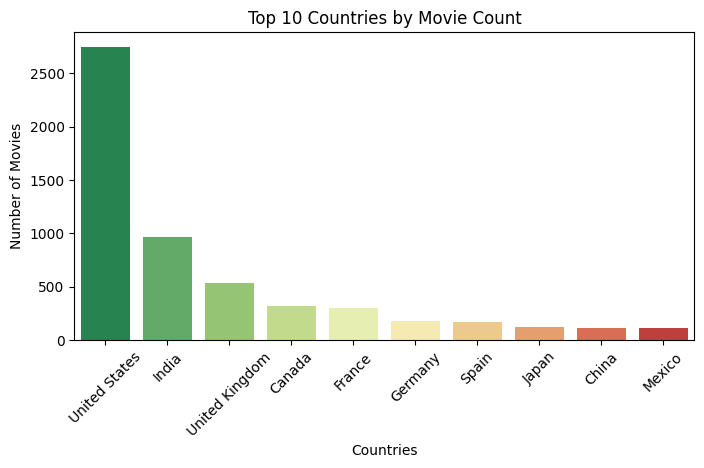

In [59]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Country_M,x='country',order=country_ord,palette=palette)
plt.xticks(rotation=45)
plt.title('Top 10 Countries by Movie Count')
plt.xlabel('Countries')
plt.ylabel('Number of Movies')
plt.show()

In [60]:
# Only Top 10 Countries TV_Shows Data
Top_10_Country_TV=data_tv_country.loc[data_tv_country['country'].isin(top_10_country_TV.index)]

# order wise Top 10 Countries based on movies production
country_ord_TV=Top_10_Country_TV['country'].value_counts().index
palett = sns.color_palette("RdYlGn_r", n_colors=len(country_ord_TV))

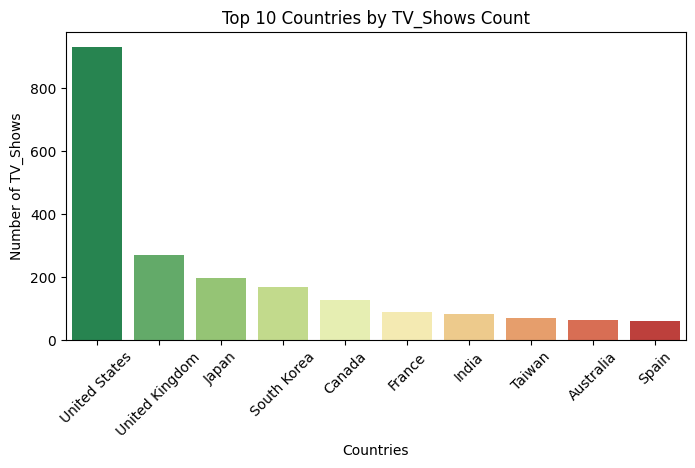

In [61]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Country_TV,x='country',order=country_ord_TV,palette=palett)
plt.xticks(rotation=45)
plt.title('Top 10 Countries by TV_Shows Count')
plt.xlabel('Countries')
plt.ylabel('Number of TV_Shows')
plt.show()

# <p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>



1.   US Dominance in Both Movies and TV_Shows production, but Heavy Movie Lean

1.   India: High Movie Focus, Low TV Output
reason might be lenthy of episodes which make loose focus on Tv Shows and Bollywood and regional movies have great demand

1.  East Asia Rules the TV Show Domain (Anime & K-Dramas) specially Japan and South Korea(mainly regional)


2.   Europe are Consistent Across Both Movies and TV_Shows production

# **(B) Top 10 Directors Based on Movies & TV Shows Production**

In [62]:
# Only Top 10 Movie Directors Data
Top_10_Director_M=data_mov_dir.loc[data_mov_dir['director'].isin(top_10_dir_M.index)]

# order wise Top 10 Movie Directors based on movies production
dir_m_ord=Top_10_Director_M['director'].value_counts().index

In [63]:
palett = sns.color_palette("RdYlGn_r", n_colors=len(dir_m_ord))

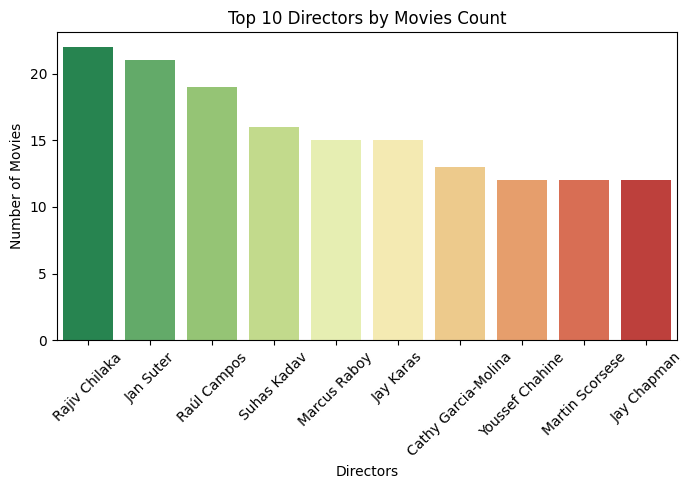

In [64]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Director_M,x='director',order=dir_m_ord,palette=palett)
plt.xticks(rotation=45)
plt.title('Top 10 Directors by Movies Count')
plt.xlabel('Directors')
plt.ylabel('Number of Movies')
plt.show()

In [65]:
# Only Top 10 TV_Shows Directors Data
Top_10_Director_Tv=data_tv_dir.loc[data_tv_dir['director'].isin(top_10_dir_TV.index)]

# order wise Top 10 TV_Shows Directors based on movies production
dir_tv_ord=Top_10_Director_Tv['director'].value_counts().index
palettu = sns.light_palette("#006400", n_colors=10, reverse=True)

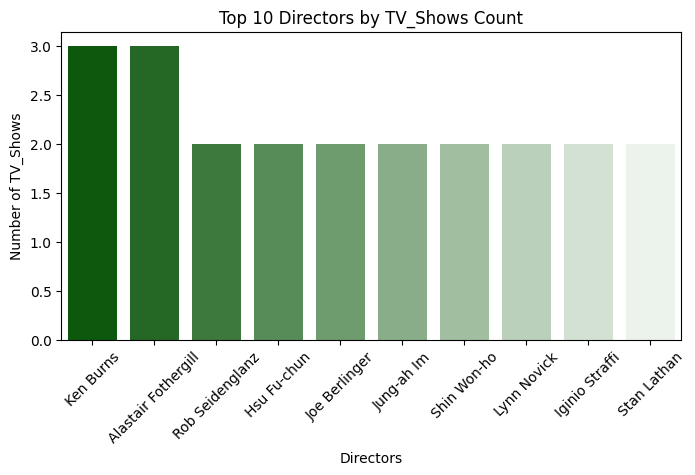

In [66]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Director_Tv,x='director',order=dir_tv_ord,palette=palettu)
plt.xticks(rotation=45)
plt.title('Top 10 Directors by TV_Shows Count')
plt.xlabel('Directors')
plt.ylabel('Number of TV_Shows')
plt.show()

# <p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
The movie director chart is dominated by prominent regional movie filmmakers & comedy directors
also Comparing Movie Director chart against the TV Show Director data reveals almost zero overlap

# **(C) Top 10 Cast Based on Movies & TV Shows Production**

In [67]:
# Only Top 10 Movie Cast Data
Top_10_Cast_M=data_mov_cast.loc[data_mov_cast['cast'].isin(top_10_cast_M.index)]

# order wise Top 10 Movie Cast based on movies production
cast_m_ord=Top_10_Cast_M['cast'].value_counts().index
palettu = sns.light_palette("#006400", n_colors=10, reverse=True)

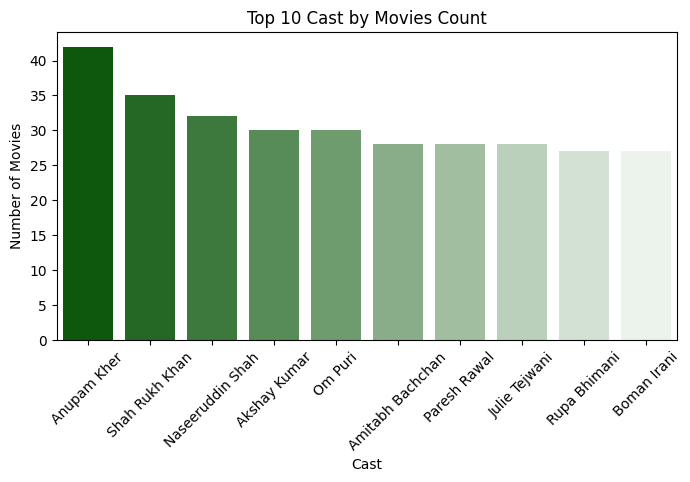

In [68]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Cast_M,x='cast',order=cast_m_ord,palette=palettu)
plt.xticks(rotation=45)
plt.title('Top 10 Cast by Movies Count')
plt.xlabel('Cast')
plt.ylabel('Number of Movies')
plt.show()

In [69]:
# Only Top 10 TV Shows Cast Data
Top_10_Cast_TV=data_tv_cast.loc[data_tv_cast['cast'].isin(top_10_cast_tv.index)]
# order wise Top 10 TV Show Cast based on movies production
cast_tv_ord=Top_10_Cast_TV['cast'].value_counts().index
palett = sns.color_palette("RdYlGn_r", n_colors=len(cast_tv_ord))

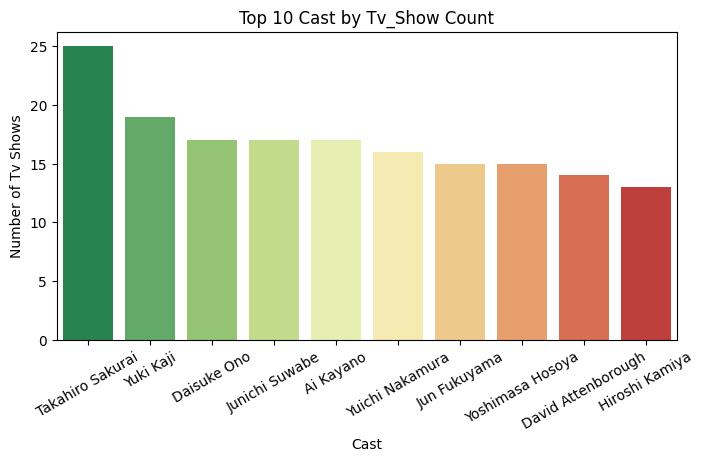

In [70]:
plt.figure(figsize=(8,4))
sns.countplot(data=Top_10_Cast_TV,x='cast',order=cast_tv_ord,palette=palett)
plt.xticks(rotation=30)
plt.title('Top 10 Cast by Tv_Show Count')
plt.xlabel('Cast')
plt.ylabel('Number of Tv Shows')
plt.show()

# <p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
Indian actors dominate the film catalog (driven by Bollywood star power), while East Asian talent leads TV Shows, reflecting distinct regional acquisition strategies.

Anime and dubbed content feature high-volume voice actors across both formats
movies and tv shows actors operate in separate at Netflix, showing that stardom rarely translates across both formats on the platform.

# **(D) Distribution of Target Audience Ratings by Category For Both Movies and TV_Shows**

In [71]:
# Only Top 10 Dominant_Rating data
Dominant_Rating=data_movies.loc[data_movies['rating'].isin(rate_m.index)]

# order wise Top Dominant_Rating category based on movies production
dom_r_ord=Dominant_Rating['rating'].value_counts().index
palett = sns.color_palette("RdYlGn_r", n_colors=len(dom_r_ord))

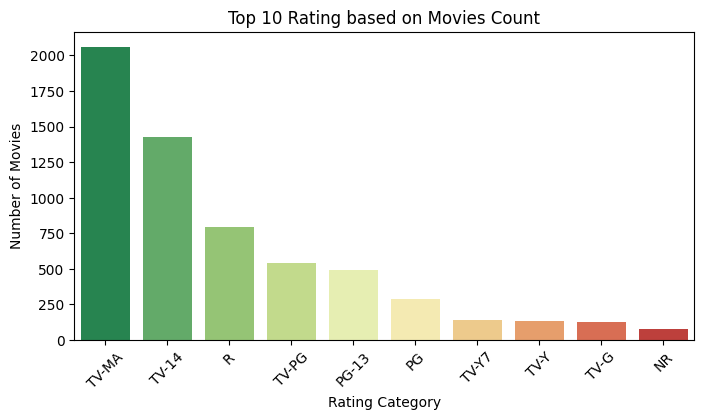

In [72]:
plt.figure(figsize=(8,4))
sns.countplot(data=Dominant_Rating,x='rating',order=dom_r_ord,palette=palett)
plt.xticks(rotation=45)
plt.rcParams['xtick.labelsize']=10
plt.title('Top 10 Rating based on Movies Count')
plt.xlabel('Rating Category')
plt.ylabel('Number of Movies')
plt.show()

In [73]:
# Only Top 10 Dominant_Rating data based on TV Shows
Dominant_Rating_TV=data_tv.loc[data_tv['rating'].isin(rate_tv.index)]

# order wise Top Dominant_Rating category based on TV Show production
dom_r_ord_t=Dominant_Rating_TV['rating'].value_counts().index
palett = sns.color_palette("RdYlGn_r", n_colors=len(dom_r_ord_t))

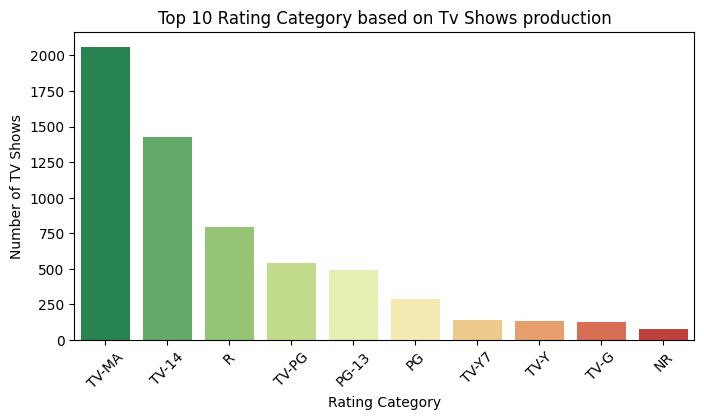

In [74]:
plt.figure(figsize=(8,4))
sns.countplot(data=Dominant_Rating,x='rating',order=dom_r_ord,palette=palett)
plt.xticks(rotation=45)
plt.rcParams['xtick.labelsize']=10
plt.title('Top 10 Rating Category based on Tv Shows production')
plt.xlabel('Rating Category')
plt.ylabel('Number of TV Shows')
plt.show()

# <p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
Over 75% of Netflix's catalog is rated TV-MA, TV-14, or R, proving the platform prioritizes mature teens and adults to drive core subscriptions.

Moderate ratings like TV-14 provide a strong secondary tier for co-viewing and broader household appeal.

Children's categories (TV-Y, TV-Y7, TV-G) make up a smaller footprint but stay tightly focused on core franchise animation.

The rating spread reflects a strategic focus on subscriber retention through high-engagement adult dramas while keeping family tier options available.

# **(E) Popular Themes & Classifications For Both Movies and TV_Shows**

In [75]:
# Only Top 10 Popular Movie Genre data
Popular_Theme=data_mov_genre.loc[data_mov_genre['genre'].isin(mov_genre.index[:10])]

# order wise Top 10 Popular Movie Genre category based on movies production
pop_g_ord=Popular_Theme['genre'].value_counts().index
palett = sns.color_palette("RdYlGn_r", n_colors=len(pop_g_ord))

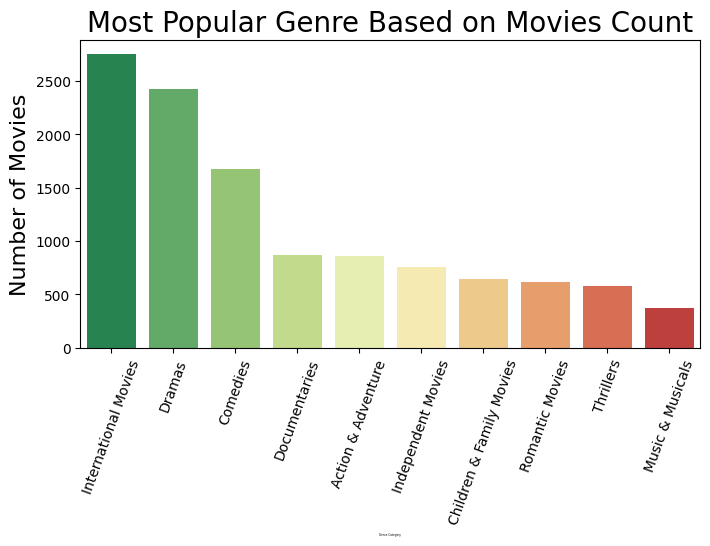

In [76]:
plt.figure(figsize=(8,4))
sns.countplot(data=Popular_Theme,x='genre',order=pop_g_ord,palette=palett)
plt.xticks(rotation=70,fontsize=10)
plt.title('Most Popular Genre Based on Movies Count',fontsize=20)
plt.xlabel('Genre Category',fontsize=2)
plt.ylabel('Number of Movies',fontsize=16)
plt.show()

In [77]:
# Only Top 10 Popular Movie Genre data
Popular_Theme_t=data_tv_genre.loc[data_tv_genre['genre'].isin(tv_genre.index[:10])]

# order wise Top 10 Popular Movie Genre category based on movies production
pop_g_ord_t=Popular_Theme_t['genre'].value_counts().index

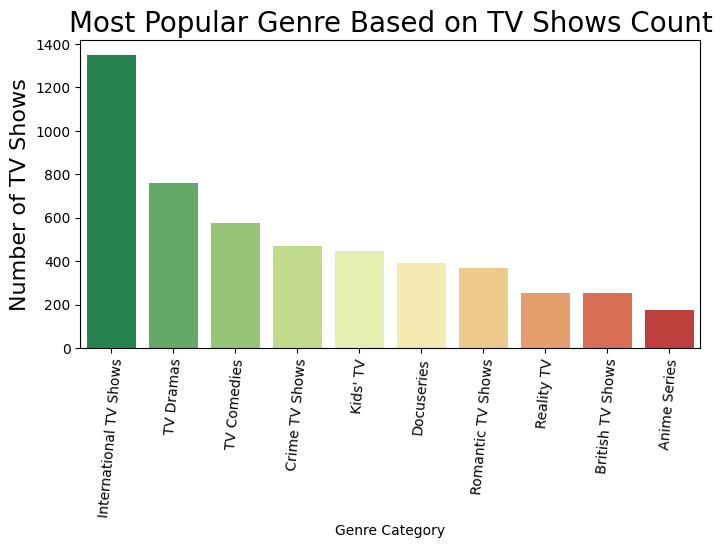

In [78]:
plt.figure(figsize=(8,4))
sns.countplot(data=Popular_Theme_t,x='genre',order=pop_g_ord_t,palette=palett)
plt.xticks(rotation=85,fontsize=10)
plt.title('Most Popular Genre Based on TV Shows Count',fontsize=20)
plt.xlabel('Genre Category')
plt.ylabel('Number of TV Shows',fontsize=16)
plt.show()

# <p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
International titles, Dramas, and Comedies form the core foundation of Netflix’s catalog across both Movies and TV Shows.

Family, Kids, and Romance content show steady engagement across both feature film and series formats.

documentary feature movies heavily outnumber multi-episode docuseries, favoring single-sitting viewing.

Action and adventure stories are predominantly produced as one-off movies rather than multi-season TV series.

# (F) **Year Wise Trend Movies & TV Shows**

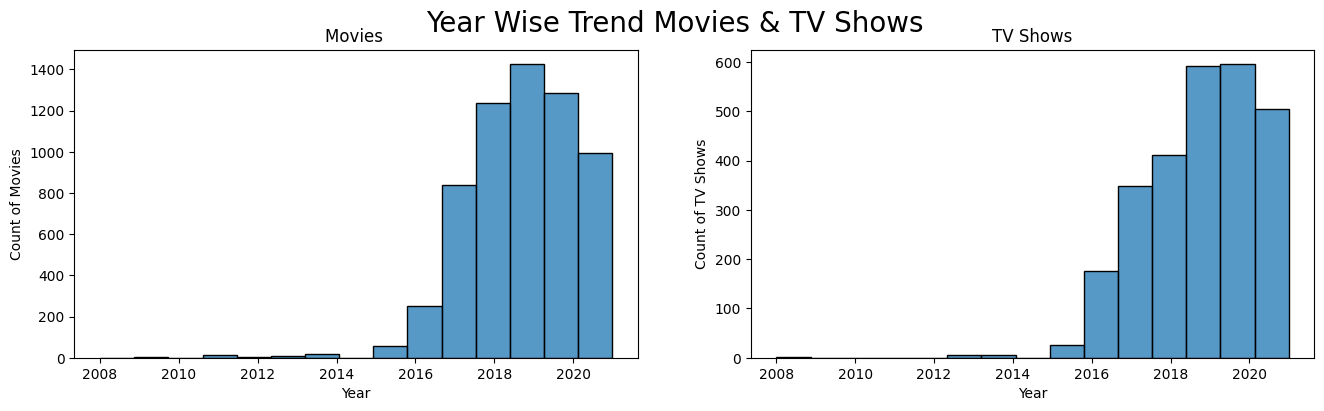

In [79]:
plt.figure(figsize=(16, 4)).suptitle('Year Wise Trend Movies & TV Shows',fontsize=20)

# Subplot 1: Movies
plt.subplot(1, 2, 1)
sns.histplot(data_movies['added year'], bins=15)
plt.title('Movies ')
plt.xlabel('Year')
plt.ylabel('Count of Movies')

# Subplot 2: TV Shows
plt.subplot(1, 2, 2)
sns.histplot(data_tv['added year'], bins=15)
plt.title('TV Shows')
plt.xlabel('Year')
plt.ylabel('Count of TV Shows')

plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

Netflix's aggressive shift toward global content acquisition specially  TV Shows after 2015 onwards

Frequency in releasing TV shows from the last couple of years are rising as we can see in the histogram plot

Frequency in releasing movie from the last couple of years are dropping as we can see in the histogram plot.

 ⚠️Data for the year 2021 should not be considered because data is till mid 2021 only




# (G) **Day Wise Trend Between Movies & TV Shows**

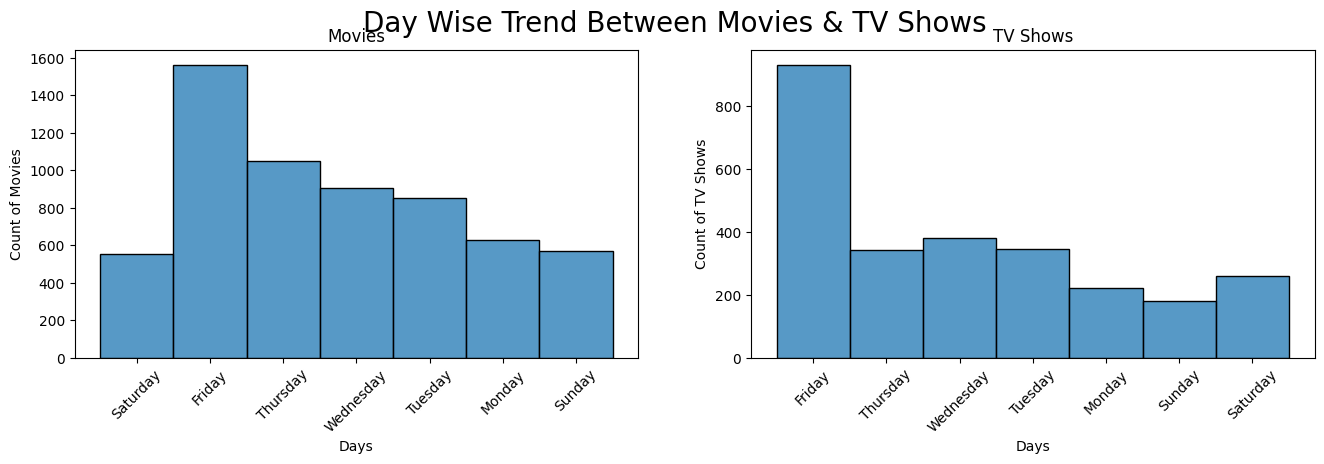

In [80]:
plt.figure(figsize=(16, 4)).suptitle('Day Wise Trend Between Movies & TV Shows',fontsize=20)

# Subplot 1: Movies
plt.subplot(1, 2, 1)
sns.histplot(data_movies['datetime'].dt.day_name(), bins=10)
plt.xticks(rotation=45)
plt.title('Movies')
plt.xlabel('Days')
plt.ylabel('Count of Movies')

# Subplot 2: TV Shows
plt.subplot(1, 2, 2)
sns.histplot(data_tv['datetime'].dt.day_name(), bins=10)
plt.xticks(rotation=45)
plt.title('TV Shows')
plt.xlabel('Days')
plt.ylabel('Count of TV Shows')

plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>
Both Movies and TV Shows experience a massive spike in additions on Fridays, making it Netflix's primary release day worldwide.

Heavy Friday drops are designed to maximize weekend binge-viewing and drive high immediate engagement as subscriber free time peaks

Mondays and Tuesdays record the lowest content additions, showing a clear strategy to avoid launching major titles on high-workload weekdays

# (H)**Session Distribution Between Movies & TV Shows**

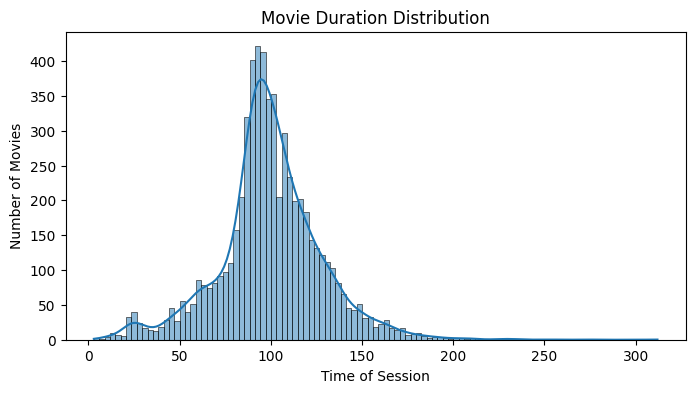

In [81]:
plt.figure(figsize=(8,4))
sns.histplot(data=data_movies, x='Number of Session', kde=True)
plt.title('Movie Duration Distribution')
plt.xlabel('Time of Session')
plt.ylabel('Number of Movies')
plt.show()

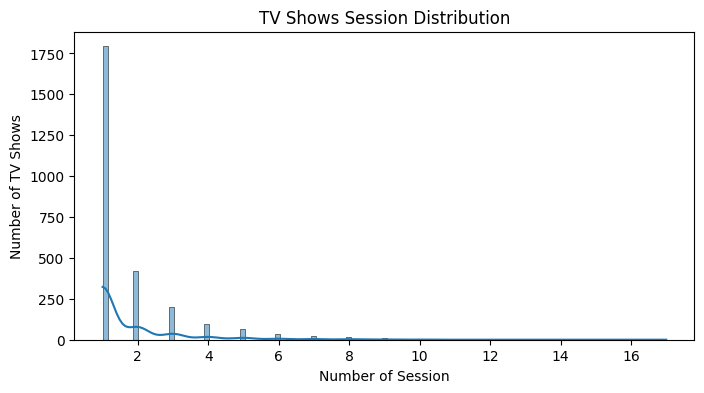

In [82]:
plt.figure(figsize=(8,4))
sns.histplot(data=data_tv, x='Number of Session', kde=True)
plt.title('TV Shows Session Distribution')
plt.ylabel('Number of TV Shows')
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

TV shows experience a sharp drop-off after Season 1,

Movie durations are tightly clustered around the 90–105 minute

# **BI_VARIATE PLOTS**
# 4.2 **For categorical variable(s): Boxplot**
# **(A) Top 4 Countries Movie & TV Shows Data 5 Points Description**

In [83]:
top_4_coun_m=top_10_country_M.index[:4]
top_4_coun_m

Index(['United States', 'India', 'United Kingdom', 'Canada'], dtype='object', name='country')

In [84]:
Top4Nation=data_mov_country[data_mov_country['country'].isin(top_4_coun_m)]

Text(0.5, 1.0, 'Top 4 Countries Movie Data 5 Points Description')

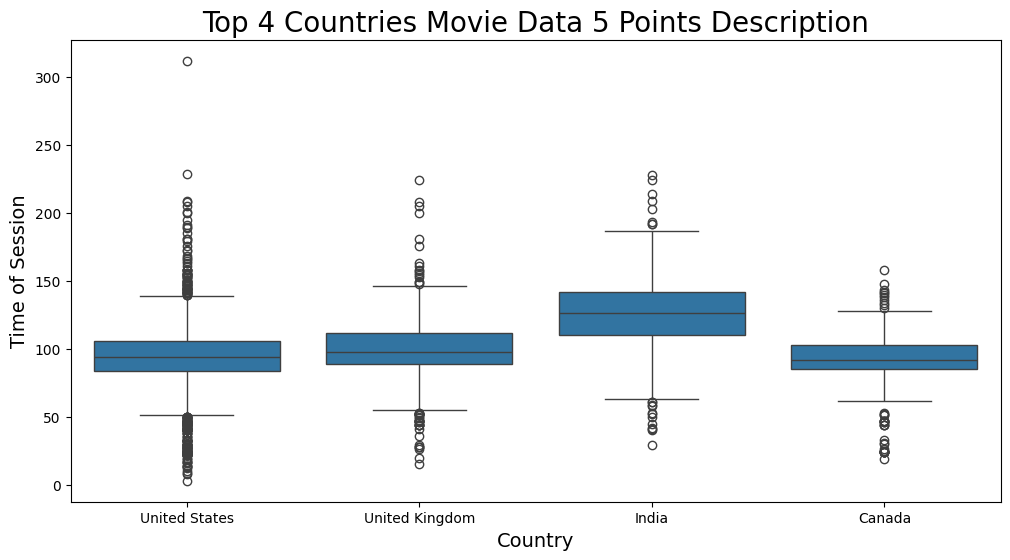

In [85]:
plt.figure(figsize=(12,6))
sns.boxplot(data=Top4Nation,x='country',y='Number of Session')
plt.xlabel('Country',fontsize=14)
plt.ylabel('Time of Session',fontsize=14)
plt.title('Top 4 Countries Movie Data 5 Points Description',fontsize=20)

In [86]:
top_4_coun_tv=top_10_country_TV.index[:4]
Top4NationTV=data_tv_country[data_tv_country['country'].isin(top_4_coun_tv)]

Text(0.5, 1.0, 'Top 4 Countries TV Shows Data 5 Points Description')

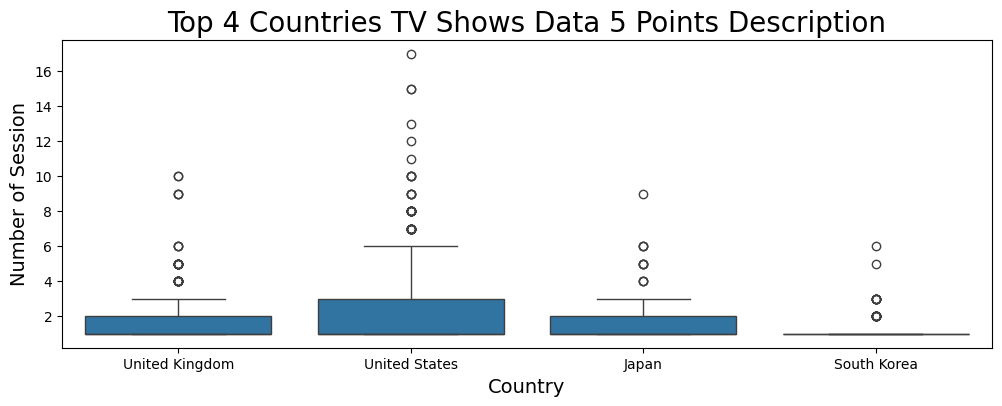

In [87]:
plt.figure(figsize=(12,4))
sns.boxplot(data=Top4NationTV,x='country',y='Number of Session')
plt.ylabel('Number of Session',fontsize=14)
plt.xlabel('Country',fontsize=14)
plt.title('Top 4 Countries TV Shows Data 5 Points Description',fontsize=20)

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

India has the highest median movie duration (120-130)mins among the top countries where as others remain(90-100 mins)
which make western movie length uniformity

TV shows from Japan and South Korea demonstrate an extreme concentration at 1 Season reflecting the popularity of self-contained limited series and single-season K-drama/anime formats.

United States and United Kingdom show a wider spread and higher outlier counts for TV show seasons

in the united states also have shon greater than 2 session in tv shows

# **(B) Movie Duration & TV Shows session Distribution Across Top Genres**

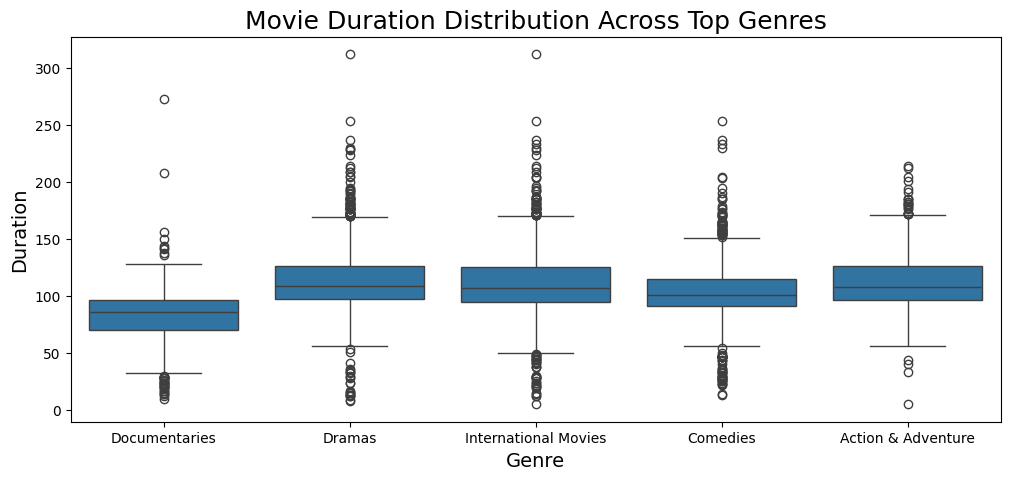

In [88]:
# Get top 5 movie genres
top_mov_genres = data_mov_genre['genre'].value_counts().head(5).index

plt.figure(figsize=(12, 5))
sns.boxplot(data=data_mov_genre[data_mov_genre['genre'].isin(top_mov_genres)], x='genre', y='Number of Session')
plt.title('Movie Duration Distribution Across Top Genres',fontsize=18)
plt.xlabel('Genre',fontsize=14)
plt.ylabel('Duration',fontsize=14)
plt.show()

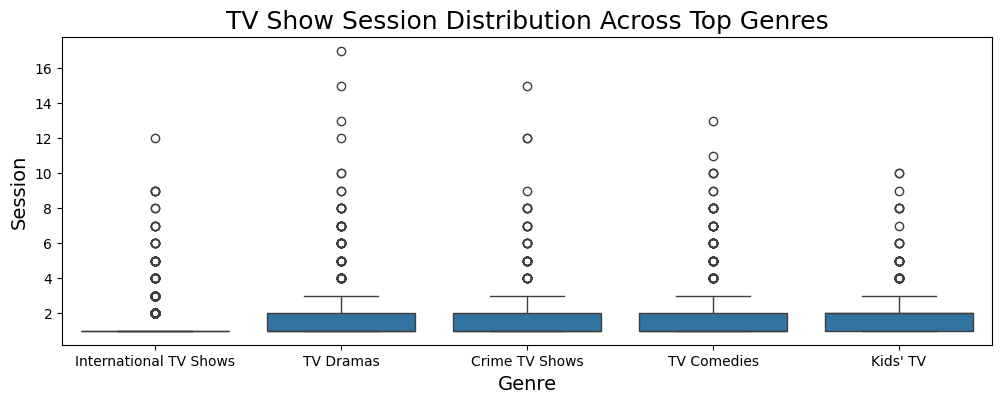

In [89]:
# Get top 5 TV Shows genres
top_tv_genres = data_tv_genre['genre'].value_counts().head(5).index

plt.figure(figsize=(12, 4))
sns.boxplot(data=data_tv_genre[data_tv_genre['genre'].isin(top_tv_genres)], x='genre', y='Number of Session')
plt.title('TV Show Session Distribution Across Top Genres',fontsize=18)
plt.xlabel('Genre',fontsize=14)
plt.ylabel('Session',fontsize=14)
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

Across major movie genres (Dramas, International Movies, Comedies, Action & Adventure), duration remain consistently centered around 90 to 110 minutes except documentaries(80-100 mins), reflecting standard streaming feature lengths.

single-season limited series dominate all TV genres.
yes TV Dramas,Crime Shows ,Comedies and kids tv show also have show might be 2nd session available but that was also limit

Multi-season as much long as >5 seassion is primarily concentrated in TV Dramas and Comedies,

# **(C) Top 5 country & Release Year Distribution & outlier check**

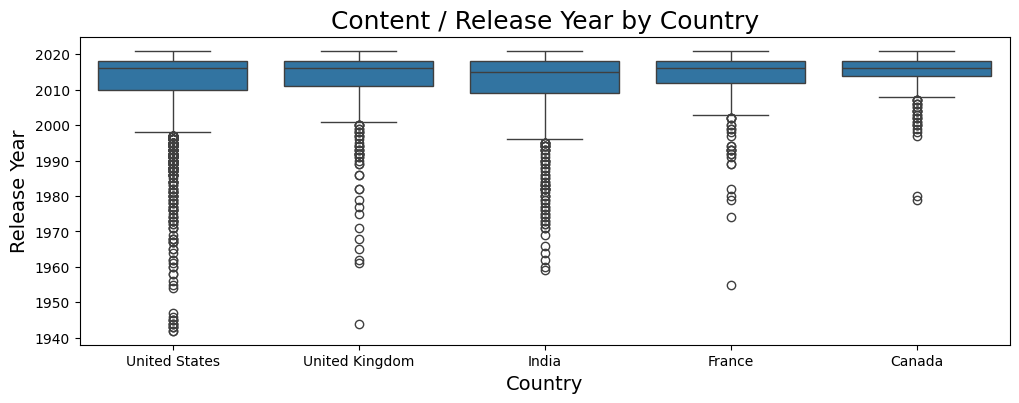

In [90]:
# Get top 5 movie countries
top_countries = data_mov_country[data_mov_country['country'] != 'Unknown_Country']['country'].value_counts().head(5).index

plt.figure(figsize=(12, 4))
sns.boxplot(data=data_mov_country[data_mov_country['country'].isin(top_countries)], x='country', y='release_year')
plt.title('Content / Release Year by Country',fontsize=18)
plt.xlabel('Country',fontsize=14)
plt.ylabel('Release Year',fontsize=14)
plt.show()

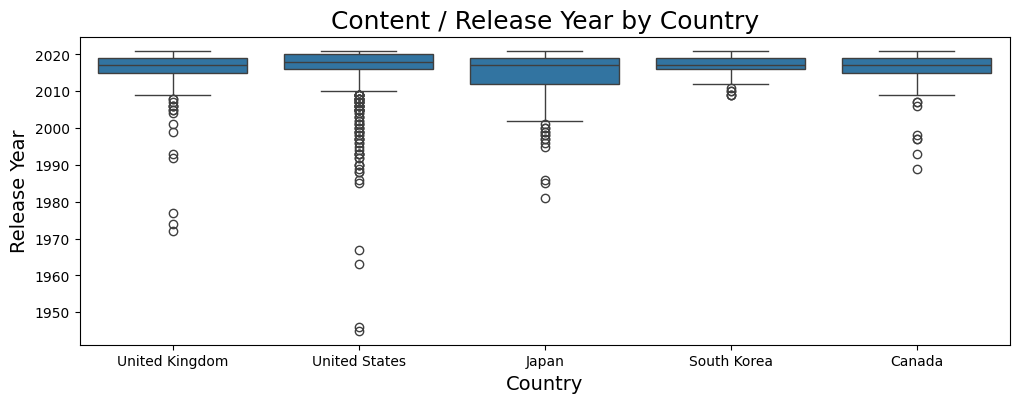

In [91]:
# Get top 5 TV Shows countries
top_countries_t = data_tv_country[data_tv_country['country'] != 'Unknown_Country']['country'].value_counts().head(5).index

plt.figure(figsize=(12, 4))
sns.boxplot(data=data_tv_country[data_tv_country['country'].isin(top_countries_t)], x='country', y='release_year')
plt.title('Content / Release Year by Country',fontsize=18)
plt.xlabel('Country',fontsize=14)
plt.ylabel('Release Year',fontsize=14)
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

Across all top production countries, TV Shows feature significantly newer release dates (mostly 2017–2021) with very narrow interquartile ranges, showing Netflix prioritizes current TV series
only Japan have older version as anime is popular from 2014 onwards

The United States exhibits the largest spread of historical content—especially for Movies—with outlier

Content from emerging markets like India and South Korea skews almost entirely modern (post-2010)
also India have vast outlier on the movie side

# **(D)Movies & TV Shows production based on top 4 country across the added year on Netflix**

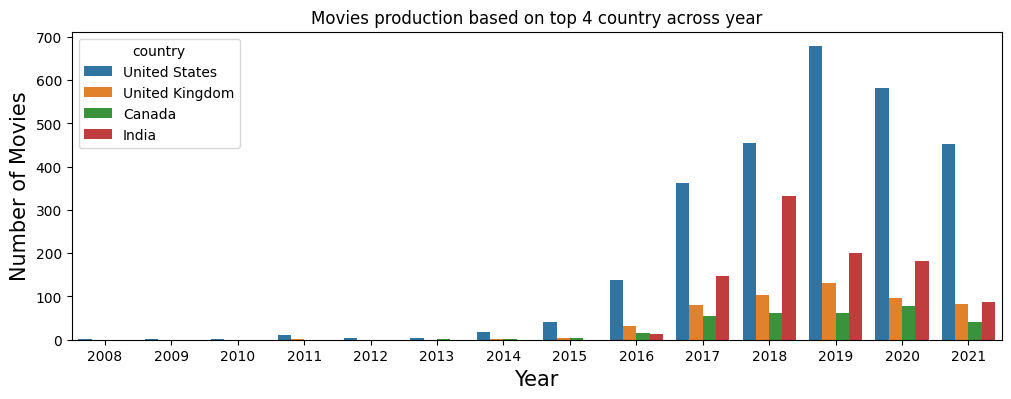

In [92]:
plt.figure(figsize=(12,4))
sns.countplot(data=Top4Nation,x='added year',hue='country')
plt.title('Movies production based on top 4 country across year')
plt.ylabel('Number of Movies',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

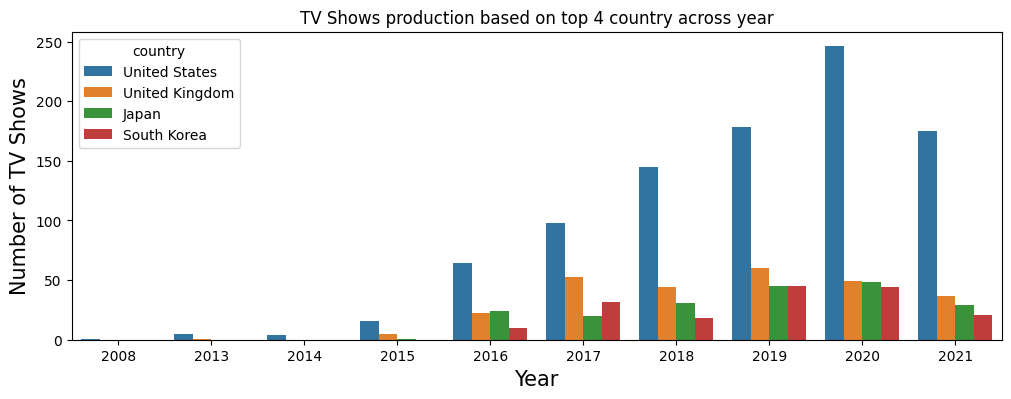

In [93]:
plt.figure(figsize=(12,4))
sns.countplot(data=Top4NationTV,x='added year',hue='country')
plt.title('TV Shows production based on top 4 country across year')
plt.ylabel('Number of TV Shows',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

The United States maintains overwhelming dominant volume across both Movies and TV Shows

India experienced a massive surge in movie additions peaking in 2018–2019, establishing itself as the second-largest movie contributor on the platform.

TV Shows additions for Asian markets (South Korea and Japan) show strong, accelerating growth from 2018 onwards, highlighting Netflix's aggressive push into K-dramas and anime.

the United Kingdom maintains a stable across both movies and TV Shows

In [94]:
Top4MovRate=data_movies[data_movies['rating'].isin(rate_m.index[:4])]

Last4Year=Top4MovRate[Top4MovRate['added year'].isin(Top4MovRate['added year'].sort_values(ascending=False).unique()[:5])]

# **(E)Movies & TV Shows production based on Last 5 year and top 4 Rating Category on Netflix**

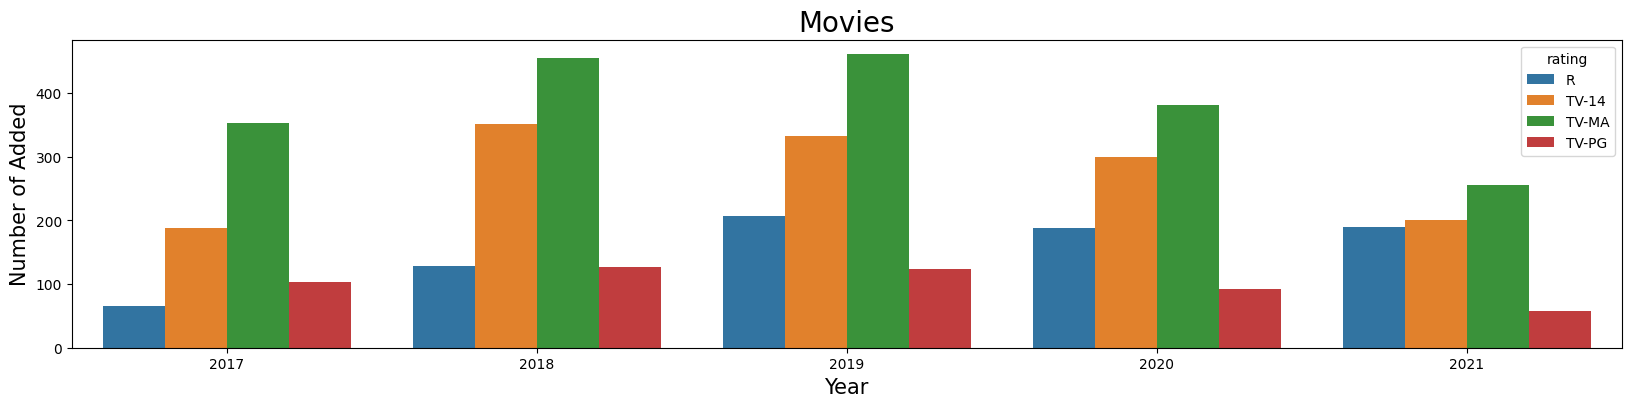

In [95]:
plt.figure(figsize=(20,4))
sns.countplot(x='added year',hue='rating',data=Last4Year)
plt.title('Movies',fontsize=20)
plt.ylabel('Number of Added',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

In [96]:
Top4TvRate=data_tv[data_tv['rating'].isin(rate_tv.index[:4])]
Last4YearTV=Top4TvRate[Top4TvRate['added year'].isin(Top4TvRate['added year'].sort_values(ascending=False).unique()[:5])]

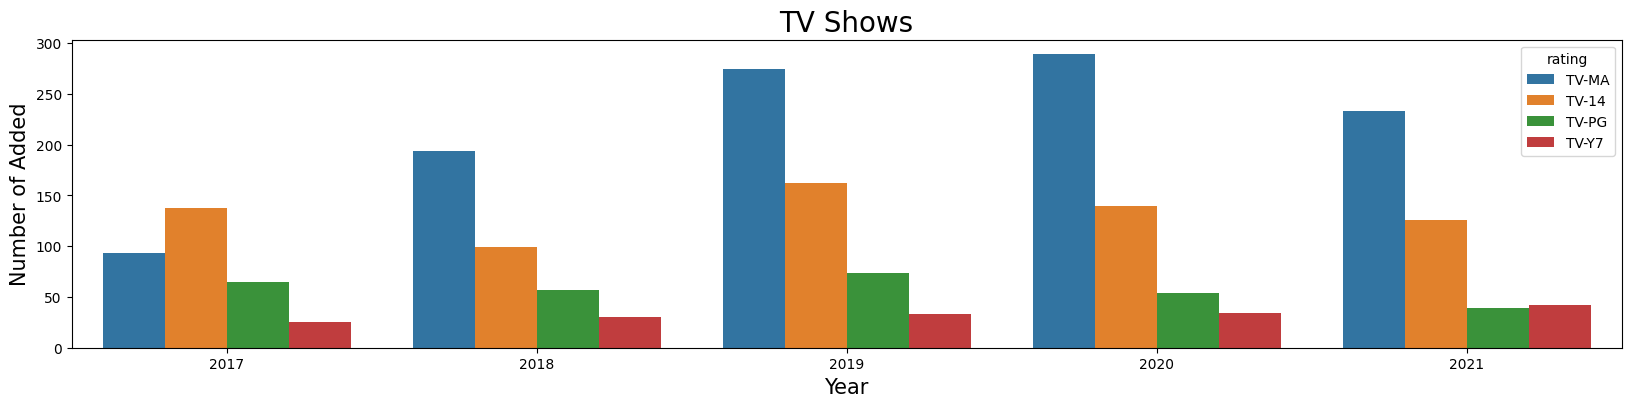

In [97]:
plt.figure(figsize=(20,4))
sns.countplot(x='added year',hue='rating',data=Last4YearTV)
plt.title('TV Shows',fontsize=20)
plt.ylabel('Number of Added',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

TV-MA consistently remains the leading content rating across recent years, highlighting Netflix's heavy investment in mature, adult-oriented programming

Higher TV Skew Toward Mature Rating
R rated movie increasing

TV-14 and TV-PG maintain a solid, steady volume year-over-year matching household and teen demographic appeal

# **(F)Movies & TV Shows production based on  Last 5 year and top 5 Genre on Netflix**

In [98]:
Top5Genre=data_mov_genre[data_mov_genre['genre'].isin(mov_genre.index[:5])]
Last5Year=Top5Genre[Top5Genre['added year'].isin(Top5Genre['added year'].sort_values(ascending=False).unique()[:5])]

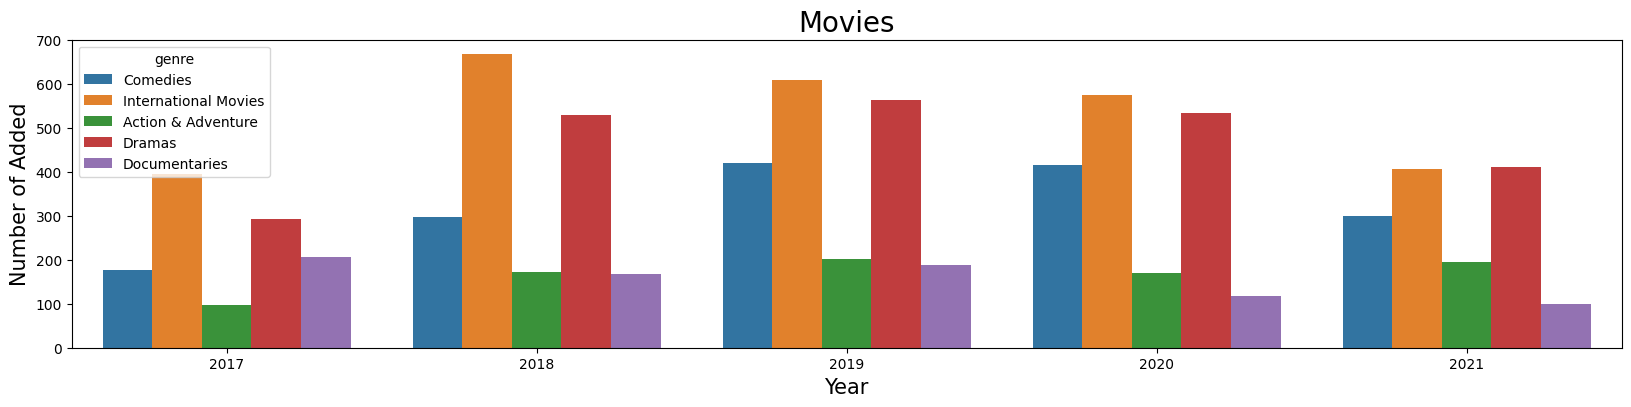

In [99]:
plt.figure(figsize=(20,4))
sns.countplot(x='added year',hue='genre',data=Last5Year)
plt.title('Movies',fontsize=20)
plt.ylabel('Number of Added',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

In [100]:
Top5TvGenre=data_tv_genre[data_tv_genre['genre'].isin(tv_genre.index[:5])]

Last5YearTv=Top5TvGenre[Top5TvGenre['added year'].isin(Top5TvGenre['added year'].sort_values(ascending=False).unique()[:5])]

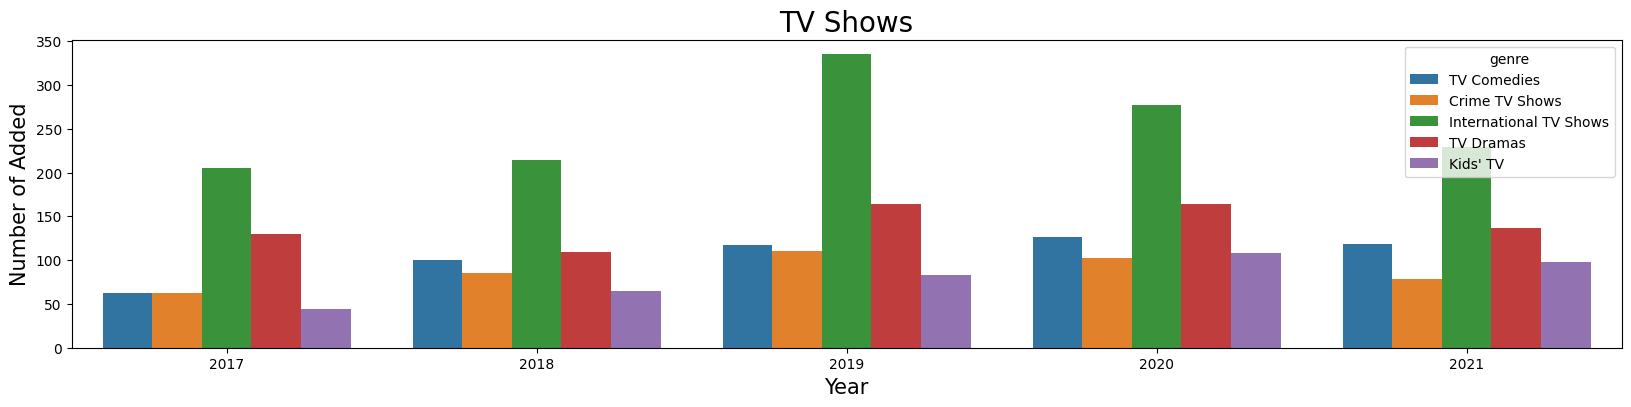

In [101]:
plt.figure(figsize=(20,4))
sns.countplot(x='added year',hue='genre',data=Last5YearTv)
plt.title('TV Shows',fontsize=20)
plt.ylabel('Number of Added',fontsize=15)
plt.xlabel('Year',fontsize=15)
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

International Movies and International TV Shows consistently lead addition counts across all 5 years but also declining state.

Dramas & comedies maintain a steady, dominant position across both Movies and TV Shows

overall all type of movie genre showing declining compared to previous year

but in other side tv shows increasing compared to previous year specially kids friendly showing growth


In [102]:
q=Last5Year['Month Name'].value_counts().index
p=Last5Year['Month Name'].value_counts().values

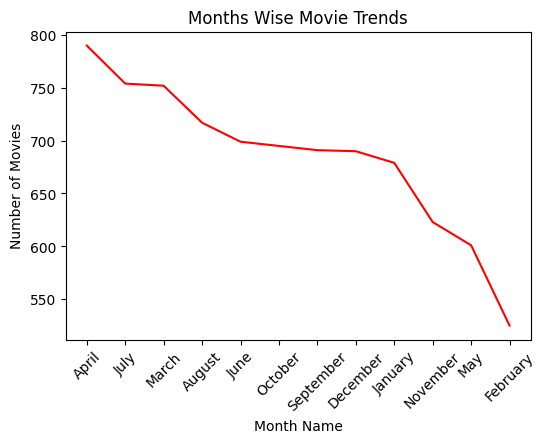

In [103]:
plt.figure(figsize=(6,4))
plt.plot(q,p,color='red')
plt.xticks(rotation=45)
plt.title('Months Wise Movie Trends')
plt.xlabel('Month Name')
plt.ylabel('Number of Movies')
plt.show()

In [104]:
y=Last5YearTv['Month Name'].value_counts(ascending=True).index
x=Last5YearTv['Month Name'].value_counts(ascending=True).values

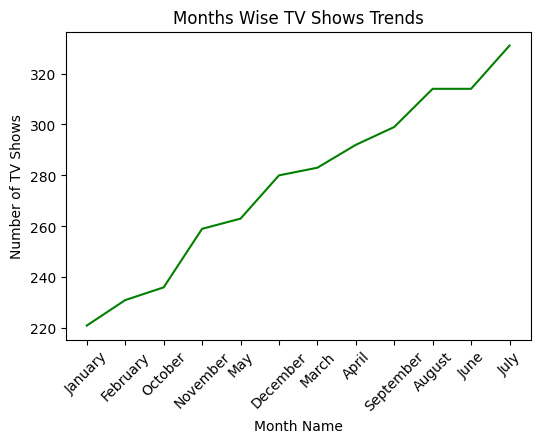

In [105]:
plt.figure(figsize=(6,4))
plt.plot(y,x,color='green')
plt.xticks(rotation=45)
plt.title('Months Wise TV Shows Trends')
plt.xlabel('Month Name')
plt.ylabel('Number of TV Shows')
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

Month of March,April,june,July,August Netflix added movies mostly

and month of April,june,July,August,september Netflix added TV Shows mostly

Netflix's context Movies serve as high-volume hooks for quick leisure viewing during vacation months.

TV Shows act as retention anchors scheduled continuously across mid-year to maintain recurring monthly active users (MAUs) ahead of Q4.


# **(H) Approx Days required  for any movies/TV Shows added to Netflix after the release of that movie/TV Shows**

In [106]:
Last5Year_movies = data_movies[(data_movies['release_year'] >= 2017) & (data_movies['days_to_netflix'] >= 0)]

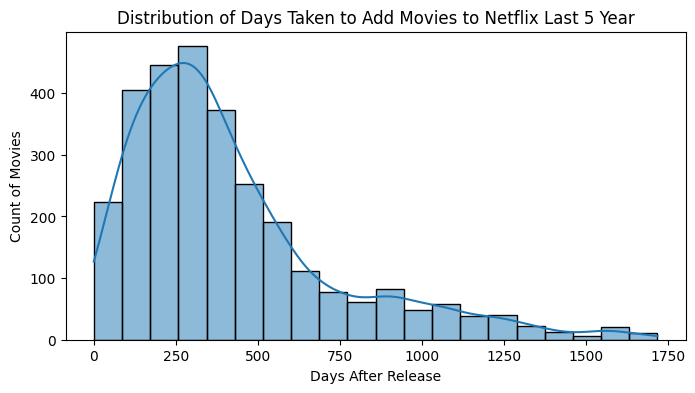

In [107]:
plt.figure(figsize=(8, 4))
sns.histplot(Last5Year_movies['days_to_netflix'], bins=20, kde=True)
plt.title('Distribution of Days Taken to Add Movies to Netflix Last 5 Year')
plt.xlabel('Days After Release')
plt.ylabel('Count of Movies')
plt.show()

In [108]:
Last5Year_tv = data_tv[(data_tv['release_year'] >= 2017) & (data_tv['days_to_netflix'] >= 0)]

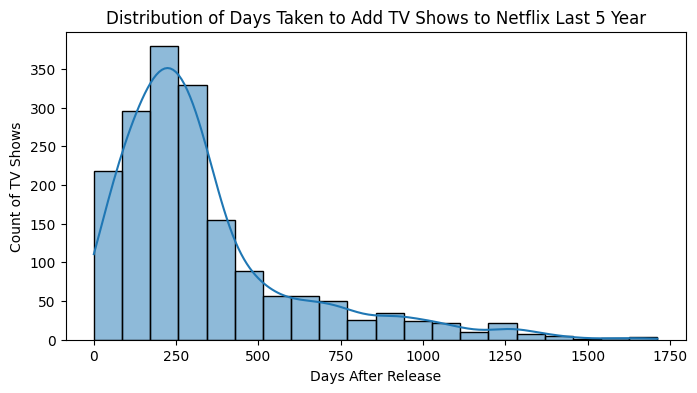

In [109]:
plt.figure(figsize=(8, 4))
sns.histplot(Last5Year_tv['days_to_netflix'], bins=20, kde=True)
plt.title('Distribution of Days Taken to Add TV Shows to Netflix Last 5 Year')
plt.xlabel('Days After Release')
plt.ylabel('Count of TV Shows')
plt.show()

<p><font size="5" color="#00796B"><b>💡 INSIGHTS<b></font></p>

Movie added 90 to 365 days (3 to 12 months) after theatrical release

but other side TV Shows added immidiately 0 to 250 days (0 to 8 months) and also sharp drop after 350 days

#  <p><font size="5" color="#1A73E8"><b>6. 🎯 Insights based on Non-Graphical and Visual Analysis

# **6.1 Comments on the range of attributes**

- **release_year**: Ranges from 1925 to 2021, but is heavily concentrated
  between 2015-2021 — the dataset is not a balanced historical archive, it's
  dominated by recent content.
- **rating**: 15 distinct rating categories exist, but just 2 (TV-MA, TV-14)
  account for over 60% of all titles.
- **duration (movies)**: Ranges from very short films (under 5 mins) to over
  300 mins for the longest titles, with most movies clustering between
  90-120 minutes.
- **duration (TV Shows)**: Ranges from 1 season to 17 seasons, but the vast
  majority (1793 titles) are just 1 Season — long-running series are rare.
- **country**: nearly 100 distinct countries appear (post un-nesting), but production
  is extremely concentrated — the US alone accounts for the largest single
  share, with a steep drop-off after the top 3-4 countries.

# **6.2 Comments on the distribution of the variables and relationship between them**



1.  Catalog Composition Heavy on Movies: The dataset exhibits a 70/30 split favoring Movies

1.   Geographic Concentration in Production: The United States leads in total additions across both formats, with India dominating secondary movie volume and South Korea / Japan driving television growth

1.  Over 30% of titles carry a TV-MA rating, demonstrating a primary platform strategy aimed at adult demographics
2.  More than 75% of content was released post-2013, showing heavy prioritization of recent stockpile


2.  country vs. Movie Duration: India shows a statistically higher median duration (115–120 mins) compared to US/UK/Canada (90–100 mins)


2.  Core genres like Dramas and Comedies show a continuous multi-decade distribution, whereas International Movies/TV and Anime are overwhelmingly concentrated in the 2017–2021



# **6.3 Comments for each univariate and bivariate plot**

**univariate :**
 Strongly skewed toward TV-MA (~30%) and TV-14, indicating Netflix’s primary subscriber base consists of young adult and mature audiences.

 75% of catalog content was released post-2013.

 Movie Runtimes: Unimodal bell curve centered between 90 and 110 minutes.
 nearly 70% of TV series stop at 1 Season

 Top performing directors and casts are mostly from asian india and east asian

 **bi-variate:**
 type vs. rating: TV Shows exhibit a noticeably higher proportion of TV-MA content compared to Movies

 country vs. duration(movies):India has a statistically higher median duration (115–120 mins) compared to Western markets like the US, UK, and Canada (90–100 mins), reflecting regional production standards and western uniformity

 country vs. Seasons(TV Shows): Asian markets (South Korea, Japan) show an extreme concentration at 1 Season (limited series / anime), whereas Western markets (US, UK) exhibit significant upper outliers with multi-season franchises

 added_year vs. genre: Core genres (Dramas, Comedies) show steady additions Last 5 years, whereas International Content, K-Dramas, and Anime show sharp exponential growth after 2018.



# <p><font size="5" color="#1A73E8"><b>7. 💼 Business Insights



1.   Content from Asian markets like South Korea and Japan (K-Dramas & Anime) and India (Bollywood) drives huge global engagement and subscriber acquisition

1.   TV Series are heavily concentrated in single-season drops (~70% have 1 season), whereas western TV shows drive long-term platform loyalty via multi-season arcs

1.   Content ingestion heavily spikes during mid-summer (W27–W31) and holiday year-end weeks (W52–W02), while spring months (W15–W18) experience clear lull periods.
2.  TV-MA content represents over 30% of the total catalog, serving as the platform's primary engagement anchor but also identified presence diverse genre


2.  Over 75% of content added features release dates post-2013, showing low subscriber demand for deep historical back-catalogs



1.  Number of releases on netflix are increasing YoY(year on year), but number of movie releases are declining a bit but Tv shows are increasing YoY




# **<p><font size="5" color="#1A73E8"><b>Q-8. 📋 Recommendations- Actionable items for business.**



1. Netflix should focus more on TV shows as 30% of total is tv shows & gaining popularity YOY

2. Netflix should focus on regional content more to diversify from international content.

1.   India,Japan,UK,South korea are the market netflix should focus on. specilly india as india has vast amount of people digital friendly and market also large

1.  Netflix should focus on comedy & kids content as these are rising globally.



2.   Based on movies perspective Netflix should prioritize of adding movie on netflix of the same year of the global release



1.  Netflix should focus on timing of release date of any tv shows like w27-w31 season 1
& w52-w02 season 2 in this way netflix can increase demand of multi season which is less prportin in east asian and india
2.  Movie release day must be Friday to Satday for highest rich

1. Promote high-quality local productions (e.g., K-Dramas, Anime, Bollywood) globally via multi-language dubbing and subtitling to boost ROI

1. Avoid clustering high-profile Original drops exclusively at the beginning of the month; stagger releases across mid-month weeks (W02–W04) to maintain consistent platform engagement.



1.  Need to build Regional hub for better reach and understanding



